In [148]:
from matplotlib import pyplot as plt
import numpy as np 
import os
import pandas as pd 
from pathlib import Path

In [149]:
from scaling.utils import (
    get_pareto_frontier, get_final_points_from_curve_set,
    functional_form_L0, fit_parametric_form
)

In [150]:
import sys

sys.path.append(str(Path(os.getcwd()).parent))

from parametric_forms import PARAMETRIC_FORMS
from iterative_fits_L0_form import data_preprocess, build_surrogate

In [151]:
PLOT_PATH = Path(os.getcwd()).absolute().parent / "plots"
PLOT_PATH.mkdir(exist_ok=True, parents=True)

In [152]:
DATA_PATH = Path(os.getcwd()).absolute().parent / "data"

In [153]:
df = pd.read_csv(DATA_PATH / "all_points_clean.csv")

In [154]:
df["flops"] = 6 * df["N_approx"] * df["D"]

In [155]:
global_train_df, global_test_df_known, global_test_df_unknown = data_preprocess(
    df, held_out_type="C", held_out_C_lower=0.6
)
global_train_df.shape, global_test_df_known.shape, global_test_df_unknown.shape

((885, 16), (5, 16), (5, 6))

In [156]:
global_test_pareto = get_pareto_frontier(
    global_test_df_known,
    x_name="flops",
    y_name="loss",
)
global_test_pareto.shape, global_test_pareto.flops.max()

((2, 16), np.float64(3.06e+21))

---

### Case A: low $C_{\text{max}}^{\text{obs}}$

In [157]:
C_FRAC_THRESHOLD=3/1000

In [158]:
# preprocess data
train_df, test_df_known, test_df_unknown = data_preprocess(
    df, held_out_type="C", held_out_C_lower=C_FRAC_THRESHOLD
)
train_df.shape, test_df_known.shape, train_df.flops.max(), test_df_known.flops.max()

((122, 16), (768, 16), np.float64(9.36e+18), np.float64(3.06e+21))

In [159]:
test_df_known = test_df_known.loc[list(set(test_df_known.index.values) - set(global_test_df_known.index.values))]
test_df_known.shape, test_df_known.flops.max()

((763, 16), np.float64(1.8e+21))

In [160]:
_test_df_pareto = get_pareto_frontier(
    test_df_known,
    x_name="flops",
    y_name="loss",
)

In [161]:
# build GP
_pred, _mse, model = build_surrogate(
    np.log(train_df["flops"].to_numpy())[:, None],
    train_df["loss"].to_numpy()[:, None],
    np.log(global_test_pareto["flops"].to_numpy()),
    model_type="gp",
    mean_form=None,
)
print(_pred)

[2.7032075 2.7032075]


In [162]:
# param fits

### on observed data only
_train_pareto = get_pareto_frontier(
    train_df,
    x_name="flops",
    y_name="loss",
)
_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _train_pareto["flops"].values, _train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _best_params))

### on observed + predicted data
_fantasized_pred = model.predict(test_df_known[["flops"]].to_numpy())

# refitting
fant_pred, fant_mse, fant_model = build_surrogate(
    np.log(np.hstack((train_df.flops.values, test_df_known.flops.values))[:, None]),
    np.hstack((train_df["loss"].values, _fantasized_pred.flatten()))[:, None],
    np.log(global_test_pareto["flops"].to_numpy()),
    model_type="gp",
    mean_form=None,
)
print(fant_pred)

# reftting parametric form
_fant_train_pareto = get_pareto_frontier(
    pd.concat((train_df, test_df_known.assign(loss=_fantasized_pred.flatten()))),
    x_name="flops",
    y_name="loss",
)
_fant_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _fant_train_pareto["flops"].values, _fant_train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
) 
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _fant_best_params))

print("=" * 50)
print(len(_train_pareto), len(_fant_train_pareto))
print(f"best params on observed data only: {_best_params}")
print(f"best params on observed + predicted data: {_fant_best_params}")

[1.95157906 1.91338769]
[2.70924758 2.74197414]
[1.95157906 1.91338769]
4 4
best params on observed data only: [ 1.38629436 12.09717391 -0.2238843 ]
best params on observed + predicted data: [ 1.38629436 12.09717391 -0.2238843 ]


/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_37316/79369641.py:10: UserWarning: You passed an edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")


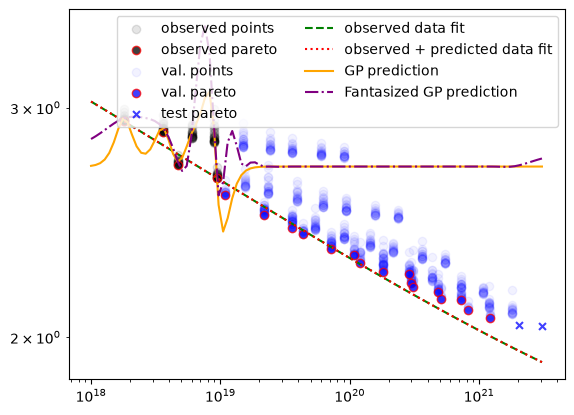

In [163]:
plt.clf()

# mark observed points
plt.scatter(train_df["flops"], train_df["loss"], color="black", label="observed points", alpha=0.1)
plt.scatter(_train_pareto["flops"], _train_pareto["loss"], color="black", label="observed pareto", alpha=0.75, edgecolor="red")

# mark test points
plt.scatter(test_df_known["flops"], test_df_known["loss"], color="blue", label="val. points", alpha=0.05)
plt.scatter(_test_df_pareto["flops"], _test_df_pareto["loss"], color="blue", label="val. pareto", alpha=0.75, edgecolor="red")
plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")

# comparing predictions
_flops = np.logspace(18, np.log10(global_test_pareto["flops"].max()), 100)

plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _best_params),
    color="green", label="observed data fit", linestyle="--"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _fant_best_params),
    color="red", label="observed + predicted data fit", linestyle=":"
)
plt.plot(
    # global_test_pareto["flops"],
    _flops,
    model.predict(np.log(_flops)[:, None]),
    color="orange", label="GP prediction", linestyle="-"
)
plt.plot(
    _flops,
    fant_model.predict(np.log(_flops)[:, None]),
    color="purple", label="Fantasized GP prediction", linestyle="-."
)

plt.xscale("log")
plt.yscale("log")
plt.legend(ncol=2)

plt.savefig(PLOT_PATH / f"low_C_std_gp.pdf", dpi=300, bbox_inches="tight")

#### Changing GP mean

In [164]:
# build GP
_pred, _mse, model = build_surrogate(
    np.log(_train_pareto.flops.to_numpy())[:, None],
    _train_pareto.loss.to_numpy()[:, None],
    # np.log(train_df["flops"].to_numpy())[:, None],
    # train_df["loss"].to_numpy()[:, None],
    np.log(global_test_pareto["flops"].to_numpy()),
    model_type="gp",
    mean_form="L0",
)
print(_pred)

### on observed + predicted data
_fantasized_pred = model.predict(test_df_known[["flops"]].to_numpy())

_new_df = pd.concat((train_df, test_df_known.assign(loss=_fantasized_pred.flatten())))
_new_df_pareto = get_pareto_frontier(
    _new_df,
    x_name="flops",
    y_name="loss",
)

# refitting
fant_pred, fant_mse, fant_model = build_surrogate(
    np.log(_new_df_pareto.flops.values)[:, None],
    _new_df_pareto.loss.values[:, None],
    np.log(global_test_pareto["flops"].to_numpy())[:, None],
    model_type="gp",
    mean_form="L0",
)
print(fant_pred)

# reftting parametric form
_fant_train_pareto = get_pareto_frontier(
    _new_df,
    x_name="flops",
    y_name="loss",
)
_fant_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _fant_train_pareto["flops"].values, _fant_train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
) 
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _fant_best_params))

print("=" * 50)
print(len(_train_pareto), len(_fant_train_pareto))
print(f"best params on observed data only: {_best_params}")
print(f"best params on observed + predicted data: {_fant_best_params}")

[2.66541229 2.70496909]
[2.66541229 2.70496909]
[1.95157906 1.91338769]
4 4
best params on observed data only: [ 1.38629436 12.09717391 -0.2238843 ]
best params on observed + predicted data: [ 1.38629436 12.09717391 -0.2238843 ]


/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_37316/3620606492.py:10: UserWarning: You passed an edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")


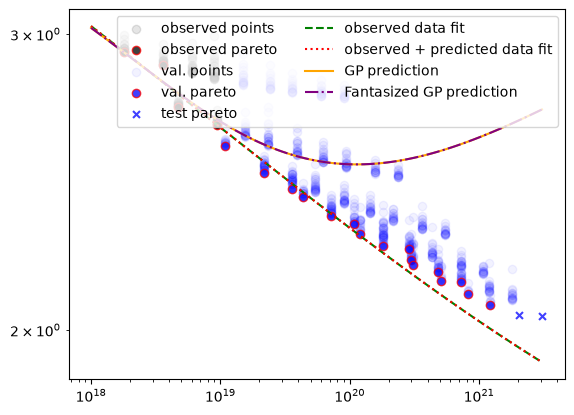

In [165]:
plt.clf()

# mark observed points
plt.scatter(train_df["flops"], train_df["loss"], color="black", label="observed points", alpha=0.1)
plt.scatter(_train_pareto["flops"], _train_pareto["loss"], color="black", label="observed pareto", alpha=0.75, edgecolor="red")

# mark test points
plt.scatter(test_df_known["flops"], test_df_known["loss"], color="blue", label="val. points", alpha=0.05)
plt.scatter(_test_df_pareto["flops"], _test_df_pareto["loss"], color="blue", label="val. pareto", alpha=0.75, edgecolor="red")
plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")

# comparing predictions
_flops = np.logspace(18, np.log10(global_test_pareto["flops"].max()), 100)

plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _best_params),
    color="green", label="observed data fit", linestyle="--"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _fant_best_params),
    color="red", label="observed + predicted data fit", linestyle=":"
)
plt.plot(
    _flops,
    model.predict(np.log(_flops)[:, None]),
    color="orange", label="GP prediction", linestyle="-"
)
plt.plot(
    _flops,
    fant_model.predict(np.log(_flops)[:, None]),
    color="purple", label="Fantasized GP prediction", linestyle="-."
)

plt.xscale("log")
plt.yscale("log")
plt.legend(ncol=2, loc="upper right")

plt.savefig(PLOT_PATH / f"low_C_L0_gp.pdf", dpi=300, bbox_inches="tight")

---

### Case B: high $C_{\text{max}}^{\text{obs}}$

In [166]:
C_FRAC_THRESHOLD=1/10

In [167]:
# preprocess data
train_df, test_df_known, test_df_unknown = data_preprocess(
    df, held_out_type="C", held_out_C_lower=C_FRAC_THRESHOLD
)
train_df.shape, test_df_known.shape, train_df.flops.max(), test_df_known.flops.max()

((689, 16), (201, 16), np.float64(3e+20), np.float64(3.06e+21))

In [168]:
test_df_known = test_df_known.loc[list(set(test_df_known.index.values) - set(global_test_df_known.index.values))]
test_df_known.shape, test_df_known.flops.max()

((196, 16), np.float64(1.8e+21))

In [169]:
_test_df_pareto = get_pareto_frontier(
    test_df_known,
    x_name="flops",
    y_name="loss",
)

In [170]:
# build GP
_pred, _mse, model = build_surrogate(
    np.log(train_df["flops"].to_numpy())[:, None],
    train_df["loss"].to_numpy()[:, None],
    np.log(global_test_pareto["flops"].to_numpy()),
    model_type="gp",
    mean_form=None,
)
print(_pred)

[2.65413423 2.65413506]


In [171]:
# param fits

### on observed data only
_train_pareto = get_pareto_frontier(
    train_df,
    x_name="flops",
    y_name="loss",
)
_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _train_pareto["flops"].values, _train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _best_params))

### on observed + predicted data
_fantasized_pred = model.predict(test_df_known[["flops"]].to_numpy())

# refitting
fant_pred, fant_mse, fant_model = build_surrogate(
    np.log(np.hstack((train_df.flops.values, test_df_known.flops.values))[:, None]),
    np.hstack((train_df["loss"].values, _fantasized_pred.flatten()))[:, None],
    np.log(global_test_pareto["flops"].to_numpy()),
    model_type="gp",
    mean_form=None,
)
print(fant_pred)

# reftting parametric form
_fant_train_pareto = get_pareto_frontier(
    pd.concat((train_df, test_df_known.assign(loss=_fantasized_pred.flatten()))),
    x_name="flops",
    y_name="loss",
)
_fant_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _fant_train_pareto["flops"].values, _fant_train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
) 
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _fant_best_params))

print("=" * 50)
print(len(_train_pareto), len(_fant_train_pareto))
print(f"best params on observed data only: {_best_params}")
print(f"best params on observed + predicted data: {_fant_best_params}")

[1.99607982 1.9605105 ]
[2.64789018 2.64223426]
[1.99607982 1.9605105 ]
14 14
best params on observed data only: [ 1.38629436 10.84845108 -0.1963931 ]
best params on observed + predicted data: [ 1.38629436 10.84845108 -0.1963931 ]


/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_37316/2397681813.py:10: UserWarning: You passed an edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")


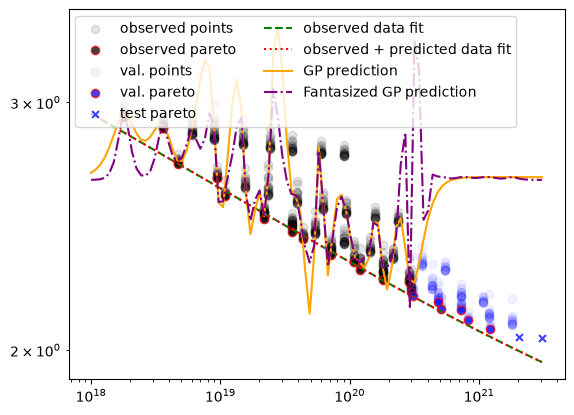

In [172]:
plt.clf()

# mark observed points
plt.scatter(train_df["flops"], train_df["loss"], color="black", label="observed points", alpha=0.1)
plt.scatter(_train_pareto["flops"], _train_pareto["loss"], color="black", label="observed pareto", alpha=0.75, edgecolor="red")

# mark test points
plt.scatter(test_df_known["flops"], test_df_known["loss"], color="blue", label="val. points", alpha=0.05)
plt.scatter(_test_df_pareto["flops"], _test_df_pareto["loss"], color="blue", label="val. pareto", alpha=0.75, edgecolor="red")
plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")

# comparing predictions
_flops = np.logspace(18, np.log10(global_test_pareto["flops"].max()), 100)

plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _best_params),
    color="green", label="observed data fit", linestyle="--"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _fant_best_params),
    color="red", label="observed + predicted data fit", linestyle=":"
)
plt.plot(
    _flops,
    model.predict(np.log(_flops)[:, None]),
    color="orange", label="GP prediction", linestyle="-"
)
plt.plot(
    _flops,
    fant_model.predict(np.log(_flops)[:, None]),
    color="purple", label="Fantasized GP prediction", linestyle="-."
)

plt.xscale("log")
plt.yscale("log")
plt.legend(ncol=2, loc="upper left")

plt.savefig(PLOT_PATH / f"high_C_std_gp.pdf", dpi=300, bbox_inches="tight")

#### Changing GP Mean

In [173]:
# build GP
_pred, _mse, model = build_surrogate(
    np.log(_train_pareto.flops.to_numpy())[:, None],
    _train_pareto.loss.to_numpy()[:, None],
    # np.log(train_df["flops"].to_numpy())[:, None],
    # train_df["loss"].to_numpy()[:, None],
    np.log(global_test_pareto["flops"].to_numpy()),
    model_type="gp",
    mean_form="L0",
)
print(_pred)

### on observed + predicted data
_fantasized_pred = model.predict(test_df_known[["flops"]].to_numpy())

_new_df = pd.concat((train_df, test_df_known.assign(loss=_fantasized_pred.flatten())))
_new_df_pareto = get_pareto_frontier(
    _new_df,
    x_name="flops",
    y_name="loss",
)

# refitting
fant_pred, fant_mse, fant_model = build_surrogate(
    np.log(_new_df_pareto.flops.values)[:, None],
    _new_df_pareto.loss.values[:, None],
    np.log(global_test_pareto["flops"].to_numpy())[:, None],
    model_type="gp",
    mean_form="L0",
)
print(fant_pred)

# reftting parametric form
_fant_train_pareto = get_pareto_frontier(
    _new_df,
    x_name="flops",
    y_name="loss",
)
_fant_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _fant_train_pareto["flops"].values, _fant_train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
) 
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _fant_best_params))

print("=" * 50)
print(len(_train_pareto), len(_fant_train_pareto))
print(f"best params on observed data only: {_best_params}")
print(f"best params on observed + predicted data: {_fant_best_params}")

[2.16135868 2.16366346]
[2.16135868 2.16366346]
[1.99607982 1.9605105 ]
14 14
best params on observed data only: [ 1.38629436 10.84845108 -0.1963931 ]
best params on observed + predicted data: [ 1.38629436 10.84845108 -0.1963931 ]


/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_37316/3789430742.py:10: UserWarning: You passed an edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")


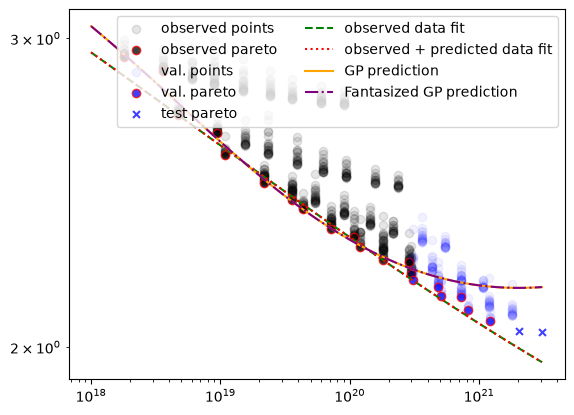

In [174]:
plt.clf()

# mark observed points
plt.scatter(train_df["flops"], train_df["loss"], color="black", label="observed points", alpha=0.1)
plt.scatter(_train_pareto["flops"], _train_pareto["loss"], color="black", label="observed pareto", alpha=0.75, edgecolor="red")

# mark test points
plt.scatter(test_df_known["flops"], test_df_known["loss"], color="blue", label="val. points", alpha=0.05)
plt.scatter(_test_df_pareto["flops"], _test_df_pareto["loss"], color="blue", label="val. pareto", alpha=0.75, edgecolor="red")
plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")

# comparing predictions
_flops = np.logspace(18, np.log10(global_test_pareto["flops"].max()), 100)

plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _best_params),
    color="green", label="observed data fit", linestyle="--"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _fant_best_params),
    color="red", label="observed + predicted data fit", linestyle=":"
)
plt.plot(
    _flops,
    model.predict(np.log(_flops)[:, None]),
    color="orange", label="GP prediction", linestyle="-"
)
plt.plot(
    _flops,
    fant_model.predict(np.log(_flops)[:, None]),
    color="purple", label="Fantasized GP prediction", linestyle="-."
)

plt.xscale("log")
plt.yscale("log")
plt.legend(ncol=2, loc="upper right")

plt.savefig(PLOT_PATH / f"high_C_L0_gp.pdf", dpi=300, bbox_inches="tight")